In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)
print("Libraries imported successfully!")

PyTorch version: 2.11.0+cpu
Device: cpu
Libraries imported successfully!


In [2]:
text = """
the sun rises in the east
the sun gives light and warmth
the moon shines in the night sky
the stars shine in the dark sky
machine learning learns patterns from data
deep learning uses neural networks
a transformer model uses self attention
self attention learns relationships between tokens
a language model predicts the next token
the next token depends on previous tokens
artificial intelligence helps computers learn
python is useful for machine learning
data helps a model discover patterns
students learn programming and mathematics
the computer processes information using algorithms
the model reads text and predicts words
attention assigns weights to relevant tokens
the transformer learns from training examples
neural networks learn from training data
computers process text using numerical vectors
a student learns artificial intelligence
the model predicts words from previous context
transformers process sequences of tokens
deep learning models learn complex patterns
"""

tokens = text.lower().split()

vocab = sorted(set(tokens))

stoi = {word: i for i, word in enumerate(vocab)}
itos = {i: word for word, i in stoi.items()}

vocab_size = len(vocab)

encoded = torch.tensor(
    [stoi[word] for word in tokens],
    dtype=torch.long
)

print("Total tokens:", len(tokens))
print("Vocabulary size:", vocab_size)
print("Sample tokens:", tokens[:15])
print("Encoded data:", encoded[:15].tolist())

Total tokens: 145
Vocabulary size: 78
Sample tokens: ['the', 'sun', 'rises', 'in', 'the', 'east', 'the', 'sun', 'gives', 'light', 'and', 'warmth', 'the', 'moon', 'shines']
Encoded data: [64, 62, 53, 22, 64, 16, 64, 62, 20, 30, 2, 75, 64, 35, 57]


In [3]:
BLOCK_SIZE = 8
BATCH_SIZE = 16

split_index = int(0.85 * len(encoded))

train_data = encoded[:split_index]
val_data = encoded[split_index:]

def get_batch(data, batch_size=BATCH_SIZE):
    if len(data) <= BLOCK_SIZE:
        raise ValueError("Dataset is too small for this block size.")

    starts = torch.randint(
        0,
        len(data) - BLOCK_SIZE,
        (batch_size,)
    )

    x = torch.stack([
        data[i:i + BLOCK_SIZE] for i in starts
    ])

    y = torch.stack([
        data[i + 1:i + BLOCK_SIZE + 1] for i in starts
    ])

    return x.to(device), y.to(device)


x, y = get_batch(train_data)

print("Input shape:", x.shape)
print("Target shape:", y.shape)

print("\nExample input:")
print([itos[i.item()] for i in x[0]])

print("\nExpected next-token targets:")
print([itos[i.item()] for i in y[0]])

Input shape: torch.Size([16, 8])
Target shape: torch.Size([16, 8])

Example input:
['tokens', 'artificial', 'intelligence', 'helps', 'computers', 'learn', 'python', 'is']

Expected next-token targets:
['artificial', 'intelligence', 'helps', 'computers', 'learn', 'python', 'is', 'useful']


In [4]:
class SelfAttention(nn.Module):
    def __init__(self, n_embd, block_size, dropout=0.1):
        super().__init__()

        self.query = nn.Linear(n_embd, n_embd)
        self.key = nn.Linear(n_embd, n_embd)
        self.value = nn.Linear(n_embd, n_embd)

        self.dropout = nn.Dropout(dropout)

        self.register_buffer(
            "mask",
            torch.tril(
                torch.ones(block_size, block_size)
            )
        )

    def forward(self, x):
        batch_size, seq_len, n_embd = x.shape

        Q = self.query(x)
        K = self.key(x)
        V = self.value(x)

        scores = Q @ K.transpose(-2, -1)

        scores = scores / math.sqrt(n_embd)

        mask = self.mask[:seq_len, :seq_len]

        scores = scores.masked_fill(
            mask == 0,
            float("-inf")
        )

        attention_weights = F.softmax(scores, dim=-1)
        attention_weights = self.dropout(attention_weights)

        output = attention_weights @ V

        return output

In [5]:
class TransformerBlock(nn.Module):
    def __init__(self, n_embd, block_size, dropout=0.1):
        super().__init__()

        self.norm1 = nn.LayerNorm(n_embd)
        self.norm2 = nn.LayerNorm(n_embd)

        self.attention = SelfAttention(
            n_embd=n_embd,
            block_size=block_size,
            dropout=dropout
        )

        self.feed_forward = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        x = x + self.attention(self.norm1(x))

        x = x + self.feed_forward(self.norm2(x))

        return x

In [6]:
class NextTokenTransformer(nn.Module):
    def __init__(
        self,
        vocab_size,
        n_embd=64,
        block_size=8,
        n_layers=2,
        dropout=0.1
    ):
        super().__init__()

        self.block_size = block_size

        self.token_embedding = nn.Embedding(
            vocab_size, n_embd
        )

        self.position_embedding = nn.Embedding(
            block_size, n_embd
        )

        self.blocks = nn.Sequential(*[
            TransformerBlock(
                n_embd=n_embd,
                block_size=block_size,
                dropout=dropout
            )
            for _ in range(n_layers)
        ])

        self.final_norm = nn.LayerNorm(n_embd)

        self.output_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        batch_size, seq_len = idx.shape

        if seq_len > self.block_size:
            raise ValueError("Input is longer than block_size.")

        positions = torch.arange(
            seq_len, device=idx.device
        )

        token_emb = self.token_embedding(idx)
        position_emb = self.position_embedding(positions)

        x = token_emb + position_emb

        x = self.blocks(x)
        x = self.final_norm(x)

        logits = self.output_head(x)

        loss = None

        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        return logits, loss

    @torch.no_grad()
    def generate(
        self,
        idx,
        max_new_tokens=20,
        temperature=0.8
    ):
        was_training = self.training
        self.eval()

        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]

            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]

            logits = logits / max(temperature, 1e-6)

            probabilities = F.softmax(logits, dim=-1)

            next_token = torch.multinomial(
                probabilities,
                num_samples=1
            )

            idx = torch.cat([idx, next_token], dim=1)

        self.train(was_training)
        return idx

In [7]:
model = NextTokenTransformer(
    vocab_size=vocab_size,
    n_embd=64,
    block_size=BLOCK_SIZE,
    n_layers=2,
    dropout=0.1
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.01
)

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(model)
print("\nTotal trainable parameters:", total_parameters)


NextTokenTransformer(
  (token_embedding): Embedding(78, 64)
  (position_embedding): Embedding(8, 64)
  (blocks): Sequential(
    (0): TransformerBlock(
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (attention): SelfAttention(
        (query): Linear(in_features=64, out_features=64, bias=True)
        (key): Linear(in_features=64, out_features=64, bias=True)
        (value): Linear(in_features=64, out_features=64, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (feed_forward): Sequential(
        (0): Linear(in_features=64, out_features=256, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=256, out_features=64, bias=True)
        (3): Dropout(p=0.1, inplace=False)
      )
    )
    (1): TransformerBlock(
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=Tr

In [8]:
EPOCHS = 300
EVAL_INTERVAL = 25

train_losses = []
val_losses = []
recorded_epochs = []

@torch.no_grad()
def estimate_loss(data, batches=10):
    model.eval()
    losses = []

    for _ in range(batches):
        xb, yb = get_batch(data)
        _, loss = model(xb, yb)
        losses.append(loss.item())

    model.train()
    return float(np.mean(losses))


for epoch in range(EPOCHS):
    model.train()

    xb, yb = get_batch(train_data)

    logits, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(), max_norm=1.0
    )

    optimizer.step()

    if (epoch + 1) % EVAL_INTERVAL == 0:
        training_loss = estimate_loss(train_data)
        validation_loss = estimate_loss(val_data)

        recorded_epochs.append(epoch + 1)
        train_losses.append(training_loss)
        val_losses.append(validation_loss)

        print(
            f"Epoch {epoch + 1:3d}/{EPOCHS} | "
            f"Training Loss: {training_loss:.4f} | "
            f"Validation Loss: {validation_loss:.4f}"
        )

print("\nTraining completed successfully!")

Epoch  25/300 | Training Loss: 3.2202 | Validation Loss: 4.4493
Epoch  50/300 | Training Loss: 1.8695 | Validation Loss: 4.5708
Epoch  75/300 | Training Loss: 1.0617 | Validation Loss: 4.5667
Epoch 100/300 | Training Loss: 0.6393 | Validation Loss: 4.8921
Epoch 125/300 | Training Loss: 0.3931 | Validation Loss: 5.0346
Epoch 150/300 | Training Loss: 0.2909 | Validation Loss: 5.3436
Epoch 175/300 | Training Loss: 0.2169 | Validation Loss: 5.7079
Epoch 200/300 | Training Loss: 0.1921 | Validation Loss: 5.7190
Epoch 225/300 | Training Loss: 0.1769 | Validation Loss: 6.0141
Epoch 250/300 | Training Loss: 0.1657 | Validation Loss: 6.2004
Epoch 275/300 | Training Loss: 0.1518 | Validation Loss: 6.2942
Epoch 300/300 | Training Loss: 0.1382 | Validation Loss: 6.2322

Training completed successfully!


In [15]:

@torch.no_grad()
def calculate_accuracy(data):
    model.eval()

    total_correct = 0
    total_tokens = 0
    total_loss = 0.0
    num_batches = 100

    for _ in range(num_batches):
        x, y = get_batch(data)

        logits, loss = model(x, y)

        predictions = torch.argmax(logits, dim=-1)

        total_correct += (predictions == y).sum().item()
        total_tokens += y.numel()
        total_loss += loss.item()

    accuracy = (total_correct / total_tokens) * 100
    average_loss = total_loss / num_batches
    perplexity = math.exp(average_loss)

    print("===== MODEL EVALUATION =====")
    print(f"Correct predictions: {total_correct}")
    print(f"Total predictions:   {total_tokens}")
    print(f"Next-token accuracy: {accuracy:.2f}%")
    print(f"Average loss:        {average_loss:.4f}")
    print(f"Perplexity:          {perplexity:.4f}")

    return accuracy

validation_accuracy = calculate_accuracy(val_data)


===== MODEL EVALUATION =====
Correct predictions: 1246
Total predictions:   12800
Next-token accuracy: 9.73%
Average loss:        6.3573
Perplexity:          576.6939


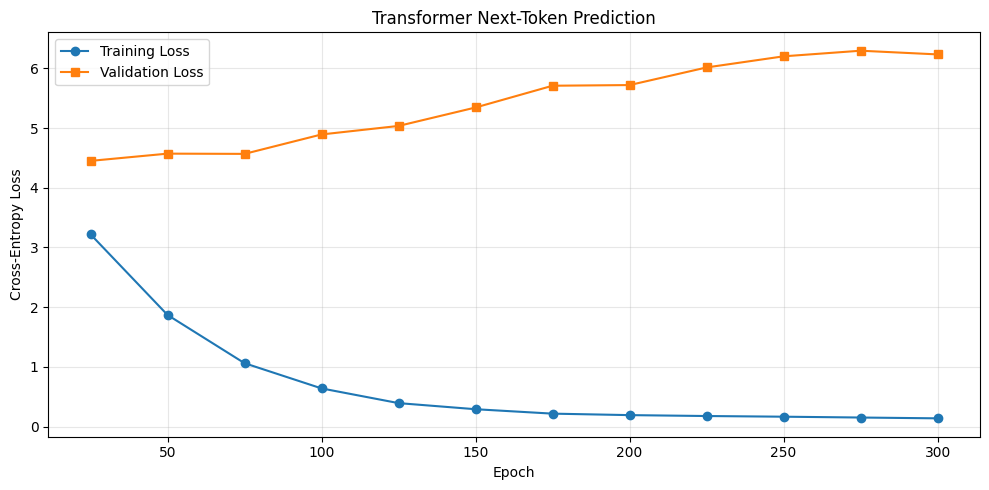

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(
    recorded_epochs,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    recorded_epochs,
    val_losses,
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Transformer Next-Token Prediction")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("training_loss.png", dpi=150)
plt.show()

In [10]:
@torch.no_grad()
def predict_next_token(prompt, top_k=5):
    model.eval()

    words = prompt.lower().split()

    if not words:
        print("Please enter some text.")
        return

    input_ids = [
        stoi.get(word, stoi["the"])
        for word in words
    ]

    input_ids = input_ids[-BLOCK_SIZE:]

    input_tensor = torch.tensor(
        [input_ids],
        dtype=torch.long,
        device=device
    )

    logits, _ = model(input_tensor)

    next_logits = logits[0, -1, :]

    probabilities = F.softmax(next_logits, dim=-1)

    top_k = min(top_k, vocab_size)

    top_probs, top_ids = torch.topk(
        probabilities, top_k
    )

    print("Input text:", prompt)
    print("\nTop next-token predictions:")

    for token_id, probability in zip(
        top_ids.tolist(), top_probs.tolist()
    ):
        print(
            f"{itos[token_id]:20s} "
            f"Probability: {probability:.4f}"
        )

    print(
        "\nMost likely next token:",
        itos[top_ids[0].item()]
    )


predict_next_token("the sun rises in")

Input text: the sun rises in

Top next-token predictions:
the                  Probability: 0.9942
self                 Probability: 0.0009
examples             Probability: 0.0004
learning             Probability: 0.0003
words                Probability: 0.0003

Most likely next token: the


In [11]:
@torch.no_grad()
def generate_text(
    prompt,
    max_new_tokens=15,
    temperature=0.8
):
    words = prompt.lower().split()

    if not words:
        raise ValueError("Please enter a starting phrase.")

    input_ids = [
        stoi.get(word, stoi["the"])
        for word in words
    ]

    context = torch.tensor(
        [input_ids],
        dtype=torch.long,
        device=device
    )

    output = model.generate(
        context,
        max_new_tokens=max_new_tokens,
        temperature=temperature
    )

    generated_ids = output[0].tolist()

    return " ".join(
        itos[token_id]
        for token_id in generated_ids
    )


print("Generated text:")
print(generate_text("the transformer", max_new_tokens=15))

Generated text:
the transformer learns from training examples neural networks learn from training data computers process text using numerical


In [12]:
@torch.no_grad()
def evaluate_model(data, batches=30):
    model.eval()
    losses = []

    for _ in range(batches):
        xb, yb = get_batch(data)
        _, loss = model(xb, yb)
        losses.append(loss.item())

    average_loss = float(np.mean(losses))
    perplexity = math.exp(average_loss)

    return average_loss, perplexity


train_loss, train_perplexity = evaluate_model(train_data)
val_loss, val_perplexity = evaluate_model(val_data)

print("=" * 40)
print("MODEL EVALUATION RESULTS")
print("=" * 40)
print(f"Training loss:       {train_loss:.4f}")
print(f"Training perplexity: {train_perplexity:.4f}")
print(f"Validation loss:     {val_loss:.4f}")
print(f"Validation perplexity: {val_perplexity:.4f}")

MODEL EVALUATION RESULTS
Training loss:       0.1423
Training perplexity: 1.1529
Validation loss:     6.4391
Validation perplexity: 625.8371


In [13]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "vocab": vocab,
    "stoi": stoi,
    "itos": itos,
    "vocab_size": vocab_size,
    "block_size": BLOCK_SIZE,
    "n_embd": 64,
    "n_layers": 2
}

torch.save(
    checkpoint,
    "/content/transformer_next_token_model.pth"
)

print("Model checkpoint saved successfully!")

Model checkpoint saved successfully!


In [14]:
from google.colab import files

files.download("/content/transformer_next_token_model.pth")
files.download("/content/training_loss.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>